# Dans ce notebook on va comparer la trajectoire de Strava et notre Trajectoire

In [203]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
import os

# Ajoute le dossier parent au chemin Python
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from utils.correction_erreur_systematique import transformation_csv_dataframe
rayon_terre = 6371000 #rayon de la terre en m

### Lecture et exploration des données 
Dans cette partie on recupère les deux CSV correspondant qu'on explore et plote

In [215]:
own_data_brut= transformation_csv_dataframe("/home/barry/pi_itineraire/IMU_GPS/data/test_mobile_2_26_250_26.csv")
own_data_kalman = transformation_csv_dataframe("/home/barry/pi_itineraire/IMU_GPS/data/acq_v2_Kalman_26_250_26.csv")
data_strava = transformation_csv_dataframe("/home/barry/pi_itineraire/Strava/2_26_250_26.csv")

In [216]:
print(own_data_brut.head())
print(data_strava.head())

      Timestamp                    UTC   Latitude  Longitude  Altitude  \
0  1.778079e+09  2026/05/06 - 14:54:33  49.385748   1.069141     71.79   
1  1.778079e+09  2026/05/06 - 14:54:33  49.385748   1.069141     71.79   
2  1.778079e+09  2026/05/06 - 14:54:33  49.385748   1.069141     71.79   
3  1.778079e+09  2026/05/06 - 14:54:33  49.385748   1.069141     71.79   
4  1.778079e+09  2026/05/06 - 14:54:33  49.385748   1.069141     71.79   

   Nb Satellites  GPS Valid   Accel X   Accel Y   Accel Z    Gyro X    Gyro Y  \
0             21          1  1.228967 -0.022875  0.022753   2.52000   4.51500   
1             21          1  1.260626 -0.068686  0.137250   6.36125   3.27250   
2             21          1  1.119411 -0.083204  0.059841  14.18375   2.04750   
3             21          1  1.044381 -0.055571  0.013664  18.05125  -5.50375   
4             21          1  1.001925 -0.037454  0.085644  20.68500 -23.26625   

     Gyro Z  
0   5.43375  
1   0.54250  
2  -5.60875  
3  -9.03875 

In [217]:
# Filtre les lignes GPS invalides AVANT de sélectionner les colonnes
# GPS Valid == 1 + Fix Quality >= 1 : position GPS confirmée
own_data2 = own_data_brut[
    (own_data_brut['GPS Valid'] == 1)
][['Latitude', 'Longitude', 'UTC']].copy()

# Le fichier Kalman n'a pas de colonne GPS Valid → filtre sur les bornes géographiques
# (lat/lon hors [-90,90]/[-180,180] = divergence Kalman certaine)
own_data3 = own_data_kalman[['Latitude', 'Longitude', 'UTC']].copy()

nb_ligne_onw_brut, _   = own_data2.shape
nb_ligne_own_kalman, _ = own_data3.shape
nb_ligne_strava, _     = data_strava.shape
print('Nombre de lignes données brutes  :', nb_ligne_onw_brut)
print('Nombre de lignes données Kalman  :', nb_ligne_own_kalman)
print('Nombre de lignes Strava          :', nb_ligne_strava)


Nombre de lignes données brutes  : 3953
Nombre de lignes données Kalman  : 4001
Nombre de lignes Strava          : 153


## Synchronisation des deux pour avoir le même time selon Strava
On transforme l'UTC qui est en string en datetime pour pouvoir faire un comparaison pour la synchronisation

In [218]:
own_data2['UTC'] = pd.to_datetime(own_data2['UTC'], format='%Y/%m/%d - %H:%M:%S', errors='coerce').copy()
own_data2 = own_data2.dropna()
own_data3['UTC'] = pd.to_datetime(own_data3['UTC'],format='%Y/%m/%d - %H:%M:%S', errors='coerce').copy()
own_data3=own_data3.dropna()
data_strava['UTC'] = pd.to_datetime(data_strava['UTC'],format='%Y/%m/%d - %H:%M:%S', errors='coerce').copy()
data_strava=data_strava.dropna()


print(own_data2.describe())
print(own_data3.describe())
print(data_strava.describe())

          Latitude    Longitude                            UTC
count  3920.000000  3920.000000                           3920
mean     49.618448     1.669675  2026-05-06 14:55:50.579847168
min      49.384838     1.069141            2026-05-06 14:54:33
25%      49.385160     1.069512            2026-05-06 14:55:12
50%      49.385452     1.070041            2026-05-06 14:55:51
75%      49.385602     1.070507            2026-05-06 14:56:29
max     177.385710   262.046202            2026-05-06 14:57:08
std       5.405348    10.136757                            NaN
          Latitude    Longitude                            UTC
count  3919.000000  3919.000000                           3919
mean     49.385382     1.070005  2026-05-06 14:55:50.599642624
min      49.384840     1.069141            2026-05-06 14:54:33
25%      49.385160     1.069498            2026-05-06 14:55:12
50%      49.385447     1.070039            2026-05-06 14:55:51
75%      49.385601     1.070497            2026-05-06 1

#### Fonction de synchronisation des données à une fréquence de 1(Hz)
On prend pour le brut et le kalman le prémière acuqistion de chaque séconde 

In [219]:
def sync(df1, df2, df3, col_time='UTC'):
    dfs = [df1.copy(), df2.copy(), df3.copy()]
    result = []
    for df in dfs:
        df[col_time] = pd.to_datetime(df[col_time])
        df[col_time] = df[col_time].dt.floor('s')
        
        # Garder uniquement la première acquisition de chaque seconde
        df = df.drop_duplicates(subset=[col_time], keep='first')
        df = df.set_index(col_time)
        result.append(df)

    # Intersection des trois index
    common = result[0].index
    for df in result[1:]:
        common = common.intersection(df.index)

    print(f"Points communs (3 df): {len(common)}")
    print(f"Plage temporelle: {common.min()} → {common.max()}")
    return tuple(df.loc[common].reset_index() for df in result)

In [209]:
own_data_brut_sync,own_data_kalman_sync , data_strava_sync =sync(own_data2,own_data3,data_strava)
print("data brut",own_data_brut_sync.describe())
print("data strava",data_strava_sync.describe())
print("data kalman",own_data_kalman_sync)

Points communs (3 df): 956
Plage temporelle: 2026-05-21 18:36:27 → 2026-05-21 19:02:01
data brut                                  UTC    Latitude   Longitude
count                            956  956.000000  956.000000
mean   2026-05-21 18:49:18.054393344   48.672691    1.130168
min              2026-05-21 18:36:27    0.810167    1.071664
25%    2026-05-21 18:43:02.750000128   49.385071    1.077568
50%       2026-05-21 18:49:34.500000   49.386630    1.080392
75%    2026-05-21 18:55:38.249999872   49.387772    1.082438
max              2026-05-21 19:02:01   49.396667   49.388280
std                              NaN    5.663544    1.562417
data strava                                  UTC    Latitude   Longitude
count                            956  956.000000  956.000000
mean   2026-05-21 18:49:18.054393344   49.386529    1.079645
min              2026-05-21 18:36:27   49.384051    1.071704
25%    2026-05-21 18:43:02.750000128   49.385155    1.077590
50%       2026-05-21 18:49:34.500000 

#### Merge des trois dataFrame
On recrée un dataFrame pour stocker la latitude et la longitude de chacun des trois df synchronisés

In [220]:
df_merged = pd.concat([
    own_data_brut_sync,
    own_data_kalman_sync[['Latitude', 'Longitude']].rename(
        columns={'Latitude': 'Lat_kalman', 'Longitude': 'Lon_kalman'}
    ),
    data_strava_sync[['Latitude', 'Longitude']].rename(
        columns={'Latitude': 'Lat_strava', 'Longitude': 'Lon_strava'}
    )
], axis=1).drop(columns=['UTC'])

df_merged.describe()

,Latitude,Longitude,Lat_kalman,Lon_kalman,Lat_strava,Lon_strava
count,956.000000,956.000000,956.000000,956.000000,956.000000,956.000000
mean,48.672691,1.130168,49.386506,1.079637,49.386529,1.079645
std,5.663544,1.562417,0.001664,0.003256,0.001667,0.003249
min,0.810167,1.071664,49.384012,1.071668,49.384051,1.071704
25%,49.385071,1.077568,49.385121,1.077573,49.385155,1.077590
50%,49.386630,1.080392,49.386688,1.080391,49.386704,1.080373
75%,49.387772,1.082438,49.387814,1.082418,49.387863,1.082416
max,49.396667,49.388280,49.389759,1.083683,49.389774,1.083685


#### Calcul de la distane entre chaque point pour pouvoir mesuré l'erreur
on base notre mesure surle calcul de la distance entre les deux points 

In [221]:
rayon_terre = 6371000  # en mètres

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    a = np.clip(a, 0, 1)  # sécurité numérique
    return 2 * rayon_terre * np.arcsin(np.sqrt(a))
    
df_merge_rmse = df_merged.copy()
df_merged['dist_brut_kalman'] = haversine(
    df_merged['Latitude'], df_merged['Longitude'],
    df_merged['Lat_kalman'], df_merged['Lon_kalman']
)

df_merged['dist_brut_strava'] = haversine(
    df_merged['Latitude'], df_merged['Longitude'],
    df_merged['Lat_strava'], df_merged['Lon_strava']
)

df_merged['dist_kalman_strava'] = haversine(
    df_merged['Lat_kalman'], df_merged['Lon_kalman'],
    df_merged['Lat_strava'], df_merged['Lon_strava']
)

df_merged.describe()

,Latitude,Longitude,Lat_kalman,Lon_kalman,Lat_strava,Lon_strava,dist_brut_kalman,dist_brut_strava,dist_kalman_strava
count,956.000000,956.000000,956.000000,956.000000,956.000000,956.000000,9.560000e+02,9.560000e+02,956.000000
mean,48.672691,1.130168,49.386506,1.079637,49.386529,1.079645,8.296910e+04,8.297177e+04,3.991745
std,5.663544,1.562417,0.001664,0.003256,0.001667,0.003249,6.390324e+05,6.390322e+05,2.624769
min,0.810167,1.071664,49.384012,1.071668,49.384051,1.071704,2.652445e-02,1.494384e-01,0.228034
25%,49.385071,1.077568,49.385121,1.077573,49.385155,1.077590,8.499482e-01,2.522905e+00,2.381804
50%,49.386630,1.080392,49.386688,1.080391,49.386704,1.080373,1.257248e+00,3.722741e+00,3.511943
75%,49.387772,1.082438,49.387814,1.082418,49.387863,1.082416,1.696348e+00,5.157358e+00,4.926731
max,49.396667,49.388280,49.389759,1.083683,49.389774,1.083685,5.401442e+06,5.401443e+06,38.918926


=== Brut vs Strava ===
  Moyenne    : 82971.7661 m
  Écart-type : 639032.1665 m
  Médiane    : 3.7227 m
  Min        : 0.1494 m
  Max        : 5401443.2672 m

=== Kalman vs Strava ===
  Moyenne    : 3.9917 m
  Écart-type : 2.6248 m
  Médiane    : 3.5119 m
  Min        : 0.2280 m
  Max        : 38.9189 m

=== Brut vs Kalman ===
  Moyenne    : 82969.1047 m
  Écart-type : 639032.4158 m
  Médiane    : 1.2572 m
  Min        : 0.0265 m
  Max        : 5401441.5225 m



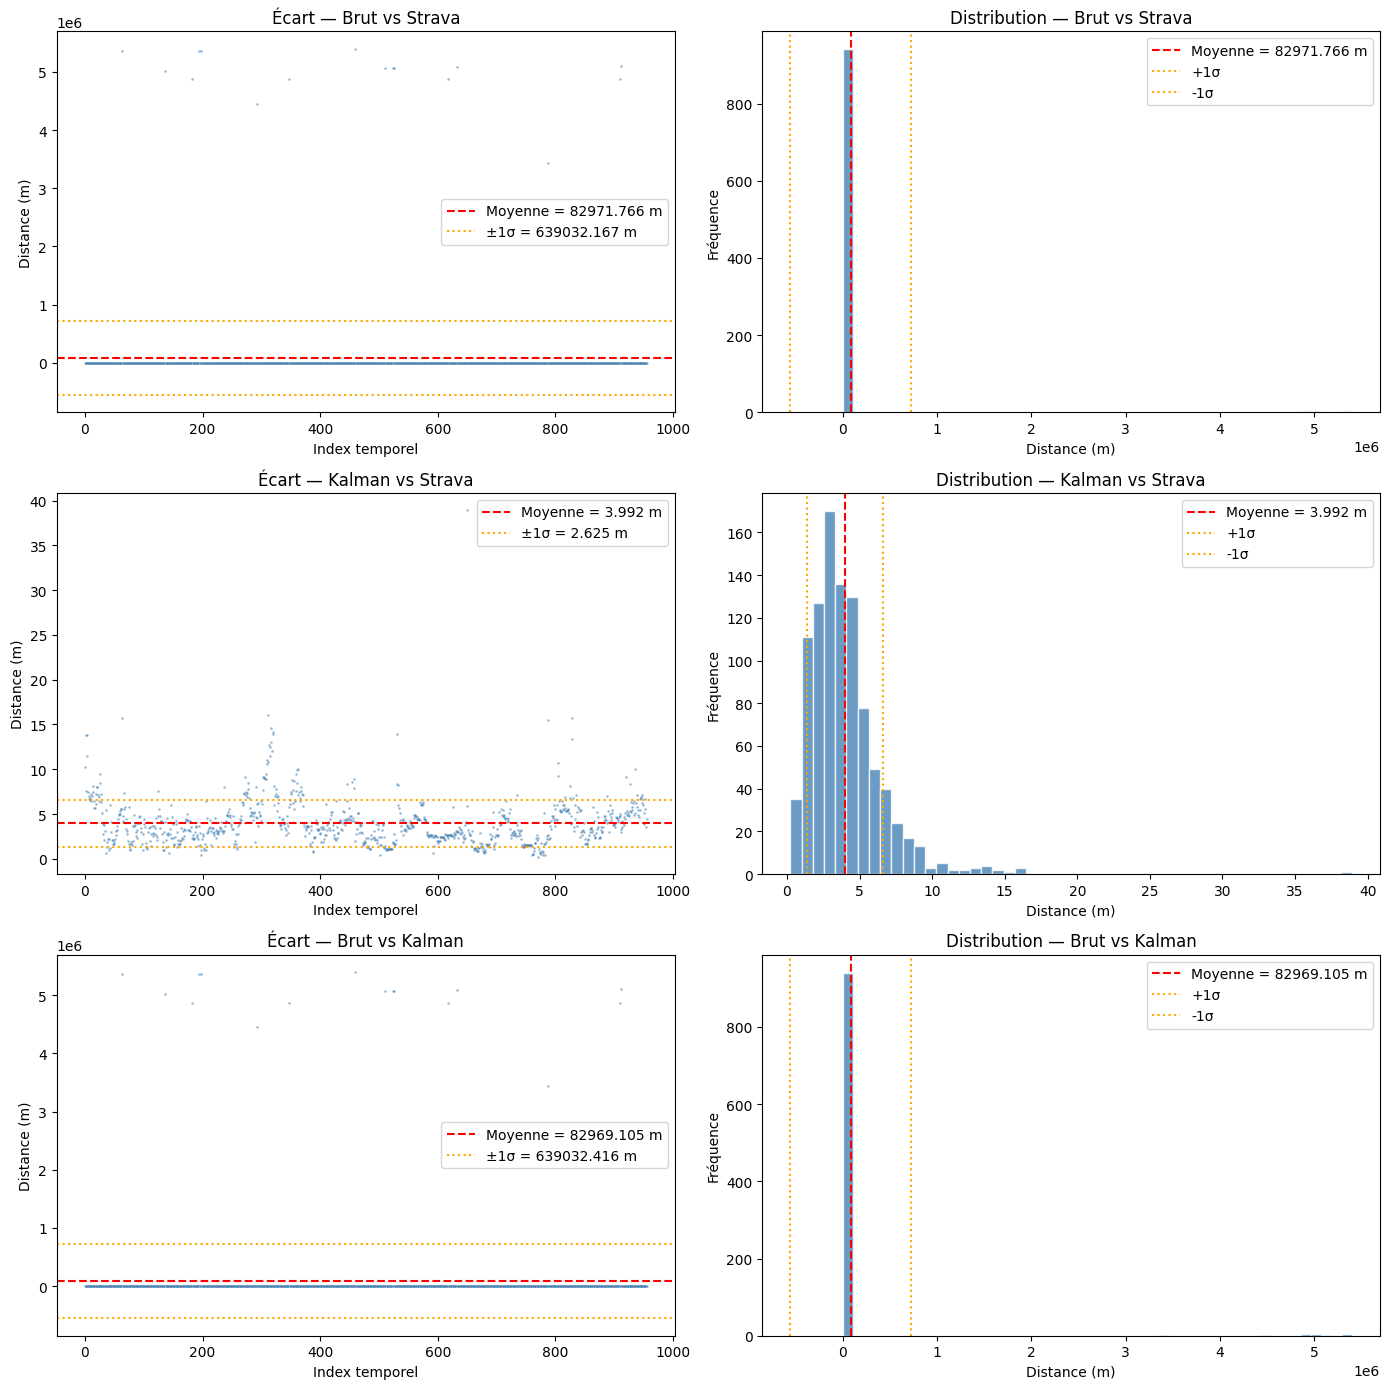

In [222]:
import matplotlib.pyplot as plt
import numpy as np

distances = {
    'Brut vs Strava':   df_merged['dist_brut_strava'],
    'Kalman vs Strava': df_merged['dist_kalman_strava'],
    'Brut vs Kalman':   df_merged['dist_brut_kalman'],
}

fig, axes = plt.subplots(3, 2, figsize=(14, 14))

for i, (label, serie) in enumerate(distances.items()):
    moyenne    = serie.mean()
    ecart_type = serie.std()
    mediane    = serie.median()

    print(f"=== {label} ===")
    print(f"  Moyenne    : {moyenne:.4f} m")
    print(f"  Écart-type : {ecart_type:.4f} m")
    print(f"  Médiane    : {mediane:.4f} m")
    print(f"  Min        : {serie.min():.4f} m")
    print(f"  Max        : {serie.max():.4f} m\n")

    # Nuage de points
    axes[i, 0].scatter(range(len(serie)), serie, s=1, alpha=0.4, color='steelblue')
    axes[i, 0].axhline(moyenne,               color='red',    linestyle='--', label=f'Moyenne = {moyenne:.3f} m')
    axes[i, 0].axhline(moyenne + ecart_type,  color='orange', linestyle=':',  label=f'±1σ = {ecart_type:.3f} m')
    axes[i, 0].axhline(moyenne - ecart_type,  color='orange', linestyle=':')
    axes[i, 0].set_xlabel("Index temporel")
    axes[i, 0].set_ylabel("Distance (m)")
    axes[i, 0].set_title(f"Écart — {label}")
    axes[i, 0].legend()

    # Histogramme
    axes[i, 1].hist(serie, bins=50, color='steelblue', edgecolor='white', alpha=0.8)
    axes[i, 1].axvline(moyenne,              color='red',    linestyle='--', label=f'Moyenne = {moyenne:.3f} m')
    axes[i, 1].axvline(moyenne + ecart_type, color='orange', linestyle=':',  label='+1σ')
    axes[i, 1].axvline(moyenne - ecart_type, color='orange', linestyle=':',  label='-1σ')
    axes[i, 1].set_xlabel("Distance (m)")
    axes[i, 1].set_ylabel("Fréquence")
    axes[i, 1].set_title(f"Distribution — {label}")
    axes[i, 1].legend()

plt.tight_layout()
plt.show()

### Implémentation RMSE pour une deuxième comparaison 

In [223]:
rmse_lat_lon = {
    'brut_vs_kalman': {
        'lat': np.sqrt(np.mean((df_merged['Latitude'] - df_merged['Lat_kalman'])**2)),
        'lon': np.sqrt(np.mean((df_merged['Longitude'] - df_merged['Lon_kalman'])**2)),
    },
    'brut_vs_strava': {
        'lat': np.sqrt(np.mean((df_merged['Latitude'] - df_merged['Lat_strava'])**2)),
        'lon': np.sqrt(np.mean((df_merged['Longitude'] - df_merged['Lon_strava'])**2)),
    },
    'kalman_vs_strava': {
        'lat': np.sqrt(np.mean((df_merged['Lat_kalman'] - df_merged['Lat_strava'])**2)),
        'lon': np.sqrt(np.mean((df_merged['Lon_kalman'] - df_merged['Lon_strava'])**2)),
    },
}

for label, vals in rmse_lat_lon.items():
    print(f"RMSE {label:25s} → lat: {vals['lat']:.6f}°  lon: {vals['lon']:.6f}°")

RMSE brut_vs_kalman            → lat: 5.705375°  lon: 1.562379°
RMSE brut_vs_strava            → lat: 5.705377°  lon: 1.562372°
RMSE kalman_vs_strava          → lat: 0.000033°  lon: 0.000042°
